In [2]:
#Step 1: Data Collection (Synthetic Resumes)
#Imports and setup
import os
import random
from itertools import product
import pandas as pd


random.seed(42)

In [3]:
#The job description and required skills
job_description = """Job Title: Data Scientist

We are looking for a Data Scientist to join our analytics team. You will clean and
analyze data, build machine learning models, and present insights to the business.

Responsibilities:
- Collect, clean, and analyze large datasets using Python, Pandas, and NumPy
- Write SQL queries to extract data from databases
- Build, train, and evaluate machine learning models using Scikit-learn
- Apply statistics to test hypotheses and validate results
- Create data visualization with Matplotlib and present findings to stakeholders
- Work in Jupyter Notebook and share code through Git

Requirements:
- Bachelor's degree in Computer Science, Statistics, Data Science, or a related field
- 2+ years of experience in data science or analytics
- Strong skills in Python, SQL, Pandas, NumPy, Scikit-learn, machine learning,
  statistics, and data visualization
- Good communication and problem-solving skills

Nice to have: Streamlit, TensorFlow, Git
"""

REQUIRED = ["Python", "SQL", "Pandas", "NumPy", "Scikit-learn", "Machine Learning",
            "Statistics", "Data Visualization", "Matplotlib", "Jupyter Notebook"]

with open("job_description.txt", "w") as f:
    f.write(job_description)
with open("required_skills.txt", "w") as f:
    f.write("\n".join(REQUIRED))

print(job_description[:200])

Job Title: Data Scientist

We are looking for a Data Scientist to join our analytics team. You will clean and
analyze data, build machine learning models, and present insights to the business.

Respon


REQUIRED is the list of 10 skills the recruiter must see. We use it later for keyword matching.

In [4]:
#Skill pools and candidate profiles
NICE = ["Streamlit", "TensorFlow", "Git", "Seaborn", "Deep Learning"]
ANALYST_OTHER = ["Excel", "Power BI", "Tableau", "Java", "PHP", "HTML", "CSS",
                 "JavaScript", "MySQL"]
UNRELATED = ["Photoshop", "Illustrator", "Graphic Design", "Accounting", "Tally",
             "Sales", "Marketing", "SEO", "Customer Service", "Teaching",
             "Lesson Planning", "Social Media"]

PROFILES = {
    "Strong": dict(
        titles=["Data Scientist", "Machine Learning Engineer", "Junior Data Scientist"],
        edu=["BS Computer Science", "BS Data Science", "MS Statistics"],
        n_req=(7, 10), n_nice=(1, 3), other=[], n_other=(0, 0), years=(2, 6)),
    "Medium": dict(
        titles=["Data Analyst", "Business Analyst", "Reporting Analyst", "MIS Executive"],
        edu=["BS Information Technology", "BBA", "BS Computer Science"],
        n_req=(3, 5), n_nice=(0, 1), other=ANALYST_OTHER, n_other=(2, 4), years=(1, 4)),
    "Weak": dict(
        titles=["Graphic Designer", "Accountant", "Marketing Executive",
                "Sales Manager", "School Teacher"],
        edu=["BBA", "B.Com", "BA", "BFA"],
        n_req=(0, 1), n_nice=(0, 0), other=UNRELATED, n_other=(4, 6), years=(1, 8)),
}

The first three lists are pools of skills to pick from: nice-to-have ones, analyst tools, and unrelated skills.
PROFILES describes each group: possible job titles, degrees, and how many required skills (n_req), nice-to-have skills, and other skills to pick. For example, a Strong resume lists 7 to 10 of the 10 required skills, a Medium one 3 to 5, and a Weak one only 0 or 1.

In [5]:
#The resume builder
SUMMARY = {
    "Strong": "Data professional with {y} years of experience building machine learning "
              "models and turning data into business insights.",
    "Medium": "Analyst with {y} years of experience preparing reports and dashboards "
              "and supporting business decisions with data.",
    "Weak": "Motivated professional with {y} years of experience as a {t}, focused on "
            "quality work and meeting deadlines.",
}
STRONG_BULLETS = [
    "Cleaned and analyzed large datasets using Python, Pandas, and NumPy.",
    "Built and evaluated machine learning models with Scikit-learn to predict customer behavior.",
    "Wrote SQL queries to extract and combine data from multiple databases.",
    "Used statistics and hypothesis testing to validate model results.",
    "Created data visualization charts with Matplotlib to present findings to stakeholders.",
    "Built a prediction web app with Streamlit and shared code on GitHub.",
]
MEDIUM_BULLETS = [
    "Prepared weekly sales reports and dashboards using Excel and Power BI.",
    "Cleaned data in spreadsheets and wrote basic SQL queries for reports.",
    "Presented monthly performance summaries to the management team.",
    "Automated small reporting tasks using simple Python scripts.",
    "Maintained internal web pages and fixed bugs in PHP and JavaScript code.",
]
WEAK_BULLETS = {
    "Graphic Designer": ["Designed posters, logos, and social media graphics for clients.",
                         "Edited photos and prepared print-ready artwork."],
    "Accountant": ["Prepared monthly accounts, invoices, and tax records.",
                   "Reconciled bank statements and managed payroll."],
    "Marketing Executive": ["Ran email and social media campaigns to grow brand awareness.",
                            "Wrote content and managed SEO for the company website."],
    "Sales Manager": ["Managed a sales team and exceeded quarterly targets.",
                      "Built long-term relationships with key customers."],
    "School Teacher": ["Planned lessons and assessed student progress.",
                       "Organized class activities and met with parents regularly."],
}
UNIS = ["City University", "National Institute of Technology", "Capital College",
        "Metro University"]


def build_resume(name, email, group):
    p = PROFILES[group]
    years = random.randint(*p["years"])
    title = random.choice(p["titles"])

    skills = random.sample(REQUIRED, random.randint(*p["n_req"]))
    skills += random.sample(NICE, random.randint(*p["n_nice"]))
    skills += random.sample(p["other"], random.randint(*p["n_other"]))
    random.shuffle(skills)

    if group == "Strong":
        bullets = random.sample(STRONG_BULLETS, 4)
    elif group == "Medium":
        bullets = random.sample(MEDIUM_BULLETS, 3)
    else:
        bullets = WEAK_BULLETS[title]

    summary = SUMMARY[group].format(y=years, t=title.lower())
    education = f"{random.choice(p['edu'])}, {random.choice(UNIS)}"
    bullet_text = "\n".join(f"- {b}" for b in bullets)

    return f"""{name}
Email: {email}

PROFESSIONAL SUMMARY
{summary}

SKILLS
{", ".join(skills)}

EXPERIENCE
{title} ({years} years)
{bullet_text}

EDUCATION
{education}
"""

The dictionaries and lists at the top are text building blocks: a summary sentence per group, and bullet points describing typical work. Strong bullets mention data science tools, Medium bullets mention reports and Excel, and Weak bullets match the person’s non-data job (a designer gets design bullets).

In [6]:
#Generate the 30 resumes
FIRST = ["Ayesha", "Ali", "Sara", "Hamza", "Fatima", "Bilal", "Hina", "Usman",
         "Maryam", "Zain", "Noor", "Omar", "Iqra", "Hassan", "Sana", "Daniyal"]
LAST = ["Khan", "Ahmed", "Malik", "Raza", "Siddiqui", "Butt", "Sheikh",
        "Qureshi", "Abbasi", "Mirza"]

names = random.sample(list(product(FIRST, LAST)), 30)
groups = ["Strong"] * 10 + ["Medium"] * 10 + ["Weak"] * 10
random.shuffle(groups)

rows = []
for i, ((first, last), group) in enumerate(zip(names, groups), start=1):
    name = f"{first} {last}"
    email = f"{first.lower()}.{last.lower()}@example.com"
    rows.append({
        "Resume_ID": f"resume_{i:02d}",
        "Name": name,
        "Group": group,
        "Resume_Text": build_resume(name, email, group),
    })

df = pd.DataFrame(rows)
print(df.shape)

(30, 4)


What’s happening:

product(FIRST, LAST) makes every first-and-last name combination, and random.sample(..., 30) picks 30 different ones, so no two candidates share a name.
groups holds 10 of each label, then random.shuffle mixes them, so the resume numbers don’t reveal the group.
The loop creates one resume per candidate and stores a row with its ID (resume_01, resume_02, ...), name, hidden group, and text. f"{i:02d}" pads numbers to two digits.
pd.DataFrame(rows) turns the list into a table.

In [7]:
#Save the files
os.makedirs("resumes", exist_ok=True)
for _, row in df.iterrows():
    with open(f"resumes/{row['Resume_ID']}.txt", "w") as f:
        f.write(row["Resume_Text"])

df.to_csv("resumes_dataset.csv", index=False)
print(len(os.listdir("resumes")), "resume files saved")

30 resume files saved


os.makedirs("resumes", exist_ok=True) creates a folder named resumes (and does nothing if it already exists).

In [8]:
#Inspect the data
print(df["Group"].value_counts())
print()
print(df["Resume_Text"].str.split().str.len().describe().round(0))

strong_example = df[df["Group"] == "Strong"].iloc[0]
weak_example = df[df["Group"] == "Weak"].iloc[0]
print("\n===== STRONG EXAMPLE =====\n", strong_example["Resume_Text"])
print("===== WEAK EXAMPLE =====\n", weak_example["Resume_Text"])

Group
Medium    10
Strong    10
Weak      10
Name: count, dtype: int64

count     30.0
mean      77.0
std       16.0
min       54.0
25%       63.0
50%       77.0
75%       96.0
max      100.0
Name: Resume_Text, dtype: float64

===== STRONG EXAMPLE =====
 Usman Khan
Email: usman.khan@example.com

PROFESSIONAL SUMMARY
Data professional with 6 years of experience building machine learning models and turning data into business insights.

SKILLS
Matplotlib, SQL, Machine Learning, Pandas, Seaborn, Jupyter Notebook, NumPy, Python, Deep Learning

EXPERIENCE
Machine Learning Engineer (6 years)
- Cleaned and analyzed large datasets using Python, Pandas, and NumPy.
- Wrote SQL queries to extract and combine data from multiple databases.
- Used statistics and hypothesis testing to validate model results.
- Built a prediction web app with Streamlit and shared code on GitHub.

EDUCATION
BS Data Science, City University

===== WEAK EXAMPLE =====
 Hina Malik
Email: hina.malik@example.com

PROFESSIONAL

value_counts() should show 10 resumes in each group.
.str.split().str.len() counts the words in each resume, and describe() gives the min, average, and max. I’d expect roughly 70 to 130 words, but that is my estimate, so check your own output.

In [9]:
#Step 2: Text Preprocessing (NLP)
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

df = pd.read_csv("resumes_dataset.csv")
job_description = open("job_description.txt").read()
REQUIRED = open("required_skills.txt").read().split("\n")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
print(df.shape, len(REQUIRED), len(stop_words))

(30, 4) 10 198


In [10]:
#See what naive cleaning does (the problem)
sample = "Built Machine Learning models using Python, Pandas & Scikit-learn in 2023!"

step1 = sample.lower()
step2 = re.sub(r"[^a-z\s]", " ", step1)
tokens = step2.split()
no_stop = [t for t in tokens if t not in stop_words]
lemmas = [lemmatizer.lemmatize(t) for t in no_stop]

print("1 lowercase  :", step1)
print("2 punctuation:", step2)
print("3 tokens     :", tokens)
print("4 stopwords  :", no_stop)
print("5 lemmatize  :", lemmas)
print("Stemmer on 'studies', 'analytics':",
      PorterStemmer().stem("studies"), PorterStemmer().stem("analytics"))

1 lowercase  : built machine learning models using python, pandas & scikit-learn in 2023!
2 punctuation: built machine learning models using python  pandas   scikit learn in      
3 tokens     : ['built', 'machine', 'learning', 'models', 'using', 'python', 'pandas', 'scikit', 'learn', 'in']
4 stopwords  : ['built', 'machine', 'learning', 'models', 'using', 'python', 'pandas', 'scikit', 'learn']
5 lemmatize  : ['built', 'machine', 'learning', 'model', 'using', 'python', 'panda', 'scikit', 'learn']
Stemmer on 'studies', 'analytics': studi analyt


In [11]:
#Protect the skills
NICE_SKILLS = ["Streamlit", "TensorFlow", "Git", "Seaborn", "Deep Learning"]
SPECIAL = {"c++": "cplusplus", "c#": "csharp", ".net": "dotnet"}

PHRASES = {}
for skill in REQUIRED + NICE_SKILLS:
    if " " in skill or "-" in skill:
        PHRASES[skill.lower()] = re.sub(r"[ \-]+", "_", skill.lower())

KEEP = set(PHRASES.values()) | set(SPECIAL.values())
KEEP |= {s.lower() for s in REQUIRED + NICE_SKILLS if " " not in s and "-" not in s}

print(PHRASES)
print(sorted(KEEP))

{'scikit-learn': 'scikit_learn', 'machine learning': 'machine_learning', 'data visualization': 'data_visualization', 'jupyter notebook': 'jupyter_notebook', 'deep learning': 'deep_learning'}
['cplusplus', 'csharp', 'data_visualization', 'deep_learning', 'dotnet', 'git', 'jupyter_notebook', 'machine_learning', 'matplotlib', 'numpy', 'pandas', 'python', 'scikit_learn', 'seaborn', 'sql', 'statistics', 'streamlit', 'tensorflow']


In [12]:
#The preprocessing function
def lemmatize(word):
    if word in KEEP:
        return word
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word), pos="v")


def preprocess(text, name=None):
    if name:
        text = text.replace(name, " ")          # blind screening: remove the name
    text = re.sub(r"\S+@\S+", " ", text)        # remove email addresses
    text = text.lower()

    for k, v in SPECIAL.items():                # C++ -> cplusplus
        text = text.replace(k, v)
    for k in sorted(PHRASES, key=len, reverse=True):
        text = text.replace(k, PHRASES[k])      # machine learning -> machine_learning

    text = re.sub(r"[^a-z_\s]", " ", text)      # keep letters and underscores only
    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    tokens = [lemmatize(t) for t in tokens]
    return " ".join(tokens)

In [13]:
#Test it on a tricky sentence
test = "Experienced in C++, C# and Scikit-learn; built Machine Learning models with Pandas & NumPy in 2023."
print(preprocess(test))

experience cplusplus csharp scikit_learn build machine_learning model pandas numpy


In [14]:
#Clean the job description and all 30 resumes
job_clean = preprocess(job_description)
df["Clean_Text"] = df.apply(lambda r: preprocess(r["Resume_Text"], r["Name"]), axis=1)

with open("job_clean.txt", "w") as f:
    f.write(job_clean)
df[["Resume_ID", "Name", "Group", "Clean_Text"]].to_csv("resumes_clean.csv", index=False)

print(job_clean[:300])

job title data scientist look data scientist join analytics team clean analyze data build machine_learning model present insight business responsibility collect clean analyze large datasets use python pandas numpy write sql query extract data database build train evaluate machine_learning model use 


In [15]:
#Verify the cleaning
df["Raw_Words"] = df["Resume_Text"].str.split().str.len()
df["Clean_Words"] = df["Clean_Text"].str.split().str.len()
print(df[["Raw_Words", "Clean_Words"]].describe().round(0))

first = df.iloc[0]
print("\nBEFORE:\n", first["Resume_Text"])
print("AFTER:\n", first["Clean_Text"])
print("Name left in text?", first["Name"].split()[0].lower() in first["Clean_Text"].split())
print("Emails left:", df["Clean_Text"].str.contains("example").sum())

print("\nShare of resumes mentioning each skill, by group:")
for skill in ["pandas", "machine_learning", "scikit_learn"]:
    share = df.groupby("Group")["Clean_Text"].apply(
        lambda s: s.str.contains(rf"\b{skill}\b").mean())
    print(skill, share.round(2).to_dict())

print("\nVocabulary size:", len(set(" ".join(df["Clean_Text"]).split())))

       Raw_Words  Clean_Words
count       30.0         30.0
mean        77.0         55.0
std         16.0         10.0
min         54.0         39.0
25%         63.0         45.0
50%         77.0         57.0
75%         96.0         65.0
max        100.0         68.0

BEFORE:
 Sara Abbasi
Email: sara.abbasi@example.com

PROFESSIONAL SUMMARY
Analyst with 1 years of experience preparing reports and dashboards and supporting business decisions with data.

SKILLS
Power BI, Data Visualization, TensorFlow, HTML, PHP, MySQL, Machine Learning, Jupyter Notebook, Pandas

EXPERIENCE
MIS Executive (1 years)
- Presented monthly performance summaries to the management team.
- Prepared weekly sales reports and dashboards using Excel and Power BI.
- Automated small reporting tasks using simple Python scripts.

EDUCATION
BS Information Technology, Capital College

AFTER:
 email professional summary analyst year experience prepare report dashboard support business decision data skill power bi data_vis

In [16]:
#Extract text from a PDF
!pip install -q pypdf reportlab

In [17]:
import textwrap
from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas
from pypdf import PdfReader


def extract_text_from_pdf(path):
    reader = PdfReader(path)
    return "\n".join((page.extract_text() or "") for page in reader.pages)


original = df.iloc[0]["Resume_Text"]
c = canvas.Canvas("sample_resume.pdf", pagesize=A4)
y = 800
for line in original.split("\n"):
    for part in textwrap.wrap(line, 95, break_on_hyphens=False) or [""]:
        if y < 40:
            c.showPage()
            y = 800
        c.drawString(50, y, part)
        y -= 14
c.save()

extracted = extract_text_from_pdf("sample_resume.pdf")
print(extracted[:300])
print("Words original vs extracted:", len(original.split()), len(extracted.split()))

Sara Abbasi
Email: sara.abbasi@example.com
PROFESSIONAL SUMMARY
Analyst with 1 years of experience preparing reports and dashboards and supporting business
decisions with data.
SKILLS
Power BI, Data Visualization, TensorFlow, HTML, PHP, MySQL, Machine Learning, Jupyter Notebook,
Pandas
EXPERIENCE
MI
Words original vs extracted: 77 77


In [18]:
#Step 3: Feature Extraction (TF-IDF)
#Load tge clean data
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

df = pd.read_csv("resumes_clean.csv")
df["Clean_Text"] = df["Clean_Text"].fillna("")
job_clean = open("job_clean.txt").read()

all_docs = list(df["Clean_Text"]) + [job_clean]
doc_ids = list(df["Resume_ID"]) + ["JOB"]

print(df.shape, len(all_docs))
print(doc_ids[-3:])

(30, 4) 31
['resume_29', 'resume_30', 'JOB']


In [19]:
#Bag of Words
cv = CountVectorizer()
bow = cv.fit_transform(all_docs)

print("Matrix shape (documents x words):", bow.shape)

words = cv.get_feature_names_out()
job_counts = pd.Series(bow[30].toarray().ravel(), index=words)
print(job_counts.sort_values(ascending=False).head(10))

Matrix shape (documents x words): (31, 196)
data                  6
statistics            3
science               3
machine_learning      3
data_visualization    2
build                 2
scientist             2
python                2
skill                 2
sql                   2
dtype: int64


In [20]:
#TF-IDF
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(all_docs)
feature_names = tfidf.get_feature_names_out()

print("Matrix shape:", tfidf_matrix.shape)


def top_terms(row, n=8):
    values = row.toarray().ravel()
    best = values.argsort()[::-1][:n]
    return [(feature_names[i], round(values[i], 3)) for i in best if values[i] > 0]


print("\nJOB DESCRIPTION top terms:")
print(top_terms(tfidf_matrix[30]))

Matrix shape: (31, 196)

JOB DESCRIPTION top terms:
[('data', np.float64(0.291)), ('analytics', np.float64(0.266)), ('science', np.float64(0.201)), ('statistics', np.float64(0.179)), ('analyze', np.float64(0.178)), ('scientist', np.float64(0.168)), ('machine_learning', np.float64(0.167)), ('git', np.float64(0.16))]


In [21]:
#BoW vs TF-IDF on one strong resume
i = df.index[df["Group"] == "Strong"][0]
print("Resume:", df.loc[i, "Resume_ID"], "| Group:", df.loc[i, "Group"])

bow_row = pd.Series(bow[i].toarray().ravel(), index=words)
print("\nBoW (raw counts), top 8:")
print(bow_row.sort_values(ascending=False).head(8))

print("\nTF-IDF, top 8:")
print(top_terms(tfidf_matrix[i]))

Resume: resume_03 | Group: Strong

BoW (raw counts), top 8:
data                4
machine_learning    3
experience          2
build               2
python              2
sql                 2
year                2
professional        2
dtype: int64

TF-IDF, top 8:
[('data', np.float64(0.315)), ('machine_learning', np.float64(0.27)), ('model', np.float64(0.227)), ('pandas', np.float64(0.209)), ('build', np.float64(0.209)), ('sql', np.float64(0.201)), ('numpy', np.float64(0.194)), ('deep_learning', np.float64(0.193))]


In [22]:
#Which words are common and which are rare?
doc_freq = np.asarray((bow > 0).sum(axis=0)).ravel()
idf_table = pd.DataFrame({"Word": words, "Docs_with_word": doc_freq, "IDF": tfidf.idf_})

check = ["experience", "python", "pandas", "machine_learning", "tensorflow",
         "photoshop", "accounting"]
print(idf_table[idf_table["Word"].isin(check)].sort_values("IDF").round(2).to_string(index=False))

print("\nMost common words (lowest IDF):")
print(idf_table.sort_values("IDF").head(8).round(2).to_string(index=False))

            Word  Docs_with_word  IDF
      experience              31 1.00
          python              19 1.47
machine_learning              17 1.58
          pandas              13 1.83
      tensorflow               7 2.39
       photoshop               4 2.86

Most common words (lowest IDF):
        Word  Docs_with_word  IDF
  experience              31 1.00
       skill              31 1.00
        year              31 1.00
   education              30 1.03
professional              30 1.03
     summary              30 1.03
       email              30 1.03
    business              21 1.37


In [23]:
#: Check the matrix
row_lengths = np.sqrt(np.asarray(tfidf_matrix.multiply(tfidf_matrix).sum(axis=1)).ravel())
print("Row lengths (should all be 1.0):", row_lengths.min().round(3), "to", row_lengths.max().round(3))

filled = tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])
print("Share of cells that are not zero:", round(filled * 100, 1), "%")

Row lengths (should all be 1.0): 1.0 to 1.0
Share of cells that are not zero: 22.9 %


In [24]:
#Save for the next steps
import joblib
import scipy.sparse as sp

sp.save_npz("tfidf_matrix.npz", tfidf_matrix)
joblib.dump(tfidf, "tfidf_vectorizer.joblib")
pd.Series(doc_ids).to_csv("doc_ids.csv", index=False, header=False)

print("Saved matrix, vectorizer, and document ids")

Saved matrix, vectorizer, and document ids


In [25]:
#Step 4: The Matching Algorithm
import scipy.sparse as sp
from sklearn.metrics.pairwise import cosine_similarity

df = pd.read_csv("resumes_clean.csv")
df["Clean_Text"] = df["Clean_Text"].fillna("")

tfidf_matrix = sp.load_npz("tfidf_matrix.npz").tocsr()
doc_ids = pd.read_csv("doc_ids.csv", header=None)[0].tolist()

n = len(df)
assert doc_ids[:-1] == df["Resume_ID"].tolist() and doc_ids[-1] == "JOB"

resume_vecs = tfidf_matrix[:n]
job_vec = tfidf_matrix[n]
print(resume_vecs.shape, job_vec.shape)

(30, 196) (1, 196)


In [26]:
#Cosine similarity
df["Cosine"] = cosine_similarity(resume_vecs, job_vec).ravel()

manual = resume_vecs[0].multiply(job_vec).sum()
print("Library:", round(df.loc[0, "Cosine"], 4), "| Manual dot product:", round(manual, 4))

print(df["Cosine"].describe().round(3))
print(df.groupby("Group")["Cosine"].agg(["mean", "min", "max"]).round(3))

Library: 0.1445 | Manual dot product: 0.1445
count    30.000
mean      0.249
std       0.226
min       0.018
25%       0.038
50%       0.159
75%       0.539
max       0.582
Name: Cosine, dtype: float64
         mean    min    max
Group                      
Medium  0.165  0.112  0.211
Strong  0.551  0.534  0.582
Weak    0.030  0.018  0.044


In [27]:
#: Keyword matching
REQUIRED = open("required_skills.txt").read().split("\n")


def to_token(skill):
    return re.sub(r"[ \-]+", "_", skill.lower())


REQ_TOKENS = {skill: to_token(skill) for skill in REQUIRED}
print(REQ_TOKENS)


def keyword_match(clean_text):
    tokens = set(clean_text.split())
    found = [s for s, t in REQ_TOKENS.items() if t in tokens]
    missing = [s for s in REQUIRED if s not in found]
    return found, missing


results = df["Clean_Text"].apply(keyword_match)
df["Found"] = results.str[0]
df["Missing"] = results.str[1]
df["Keyword"] = df["Found"].str.len() / len(REQUIRED)

print(df.groupby("Group")["Keyword"].agg(["mean", "min", "max"]).round(2))

example = df.iloc[0]
print("\n", example["Resume_ID"], "| Group:", example["Group"])
print("Found:  ", example["Found"])
print("Missing:", example["Missing"])

{'Python': 'python', 'SQL': 'sql', 'Pandas': 'pandas', 'NumPy': 'numpy', 'Scikit-learn': 'scikit_learn', 'Machine Learning': 'machine_learning', 'Statistics': 'statistics', 'Data Visualization': 'data_visualization', 'Matplotlib': 'matplotlib', 'Jupyter Notebook': 'jupyter_notebook'}
        mean  min  max
Group                 
Medium  0.49  0.4  0.6
Strong  0.89  0.8  1.0
Weak    0.03  0.0  0.1

 resume_01 | Group: Medium
Found:   ['Python', 'Pandas', 'Machine Learning', 'Data Visualization', 'Jupyter Notebook']
Missing: ['SQL', 'NumPy', 'Scikit-learn', 'Statistics', 'Matplotlib']


In [28]:
#Combine into a match score
W_COS, W_KEY = 0.5, 0.5

df["Match_Score"] = (W_COS * df["Cosine"] + W_KEY * df["Keyword"]) * 100

summary = df.groupby("Group")[["Cosine", "Keyword", "Match_Score"]].mean().round(2)
print(summary)
print(df["Match_Score"].describe().round(1))

        Cosine  Keyword  Match_Score
Group                               
Medium    0.16     0.49        32.73
Strong    0.55     0.89        72.06
Weak      0.03     0.03         2.99
count    30.0
mean     35.9
std      29.0
min       0.9
25%       6.6
50%      33.0
75%      67.0
max      78.1
Name: Match_Score, dtype: float64


In [29]:
#Where does the system make mistakes?
cols = ["Resume_ID", "Group", "Cosine", "Keyword", "Match_Score"]

print("Highest-scoring WEAK resumes:")
print(df[df["Group"] == "Weak"].nlargest(3, "Match_Score")[cols].round(2).to_string(index=False))

print("\nLowest-scoring STRONG resumes:")
print(df[df["Group"] == "Strong"].nsmallest(3, "Match_Score")[cols].round(2).to_string(index=False))

print("\nHighest MEDIUM vs lowest STRONG:",
      round(df[df["Group"] == "Medium"]["Match_Score"].max(), 1), "vs",
      round(df[df["Group"] == "Strong"]["Match_Score"].min(), 1))

Highest-scoring WEAK resumes:
Resume_ID Group  Cosine  Keyword  Match_Score
resume_17  Weak    0.04      0.1         6.84
resume_30  Weak    0.03      0.1         6.64
resume_14  Weak    0.03      0.1         6.55

Lowest-scoring STRONG resumes:
Resume_ID  Group  Cosine  Keyword  Match_Score
resume_20 Strong    0.53      0.8        66.72
resume_13 Strong    0.54      0.8        66.77
resume_03 Strong    0.54      0.8        67.06

Highest MEDIUM vs lowest STRONG: 40.6 vs 66.7


In [30]:
#Save the scores
out = df[["Resume_ID", "Name", "Group", "Cosine", "Keyword", "Match_Score",
          "Found", "Missing"]].copy()
out["Found"] = out["Found"].apply("; ".join)
out["Missing"] = out["Missing"].apply("; ".join)
out.to_csv("resume_scores.csv", index=False)
print(out.shape)

(30, 8)


In [31]:
#Step 5: Ranking and Shortlisting
#Load the scores and rank
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("resume_scores.csv")
df["Found"] = df["Found"].fillna("")
df["Missing"] = df["Missing"].fillna("")

df = df.sort_values("Match_Score", ascending=False).reset_index(drop=True)
df["Rank"] = df["Match_Score"].rank(method="min", ascending=False).astype(int)

print(df[["Rank", "Resume_ID", "Name", "Match_Score", "Cosine", "Keyword"]]
      .round(2).to_string(index=False))

 Rank Resume_ID           Name  Match_Score  Cosine  Keyword
    1 resume_21   Bilal Sheikh        78.09    0.56      1.0
    2 resume_28 Hassan Qureshi        77.34    0.55      1.0
    3 resume_07    Sara Sheikh        74.12    0.58      0.9
    4 resume_05  Bilal Qureshi        73.07    0.56      0.9
    5 resume_27 Maryam Qureshi        72.75    0.56      0.9
    6 resume_11  Ayesha Abbasi        72.69    0.55      0.9
    7 resume_10    Noor Abbasi        72.03    0.54      0.9
    8 resume_03     Usman Khan        67.06    0.54      0.8
    9 resume_13      Sara Raza        66.77    0.54      0.8
   10 resume_20   Noor Qureshi        66.72    0.53      0.8
   11 resume_29    Hamza Mirza        40.55    0.21      0.6
   12 resume_22  Omar Siddiqui        35.24    0.20      0.5
   13 resume_08   Hassan Mirza        34.72    0.19      0.5
   14 resume_24   Ayesha Ahmed        33.39    0.17      0.5
   15 resume_18     Bilal Khan        32.99    0.16      0.5
   16 resume_02  Ayesha 

In [32]:
#Look at the gaps and choose a threshold
scores = df["Match_Score"].to_numpy()
gaps = scores[:-1] - scores[1:]

top_gaps = pd.DataFrame({
    "After_Rank": np.arange(1, len(gaps) + 1),
    "Score_Above": scores[:-1],
    "Score_Below": scores[1:],
    "Gap": gaps,
}).nlargest(5, "Gap")
print(top_gaps.round(2).to_string(index=False))

i = gaps.argmax()
suggested = (scores[i] + scores[i + 1]) / 2
print("\nBiggest gap is after rank", i + 1)
print("Suggested threshold (middle of the gap):", round(suggested, 1))

 After_Rank  Score_Above  Score_Below   Gap
         10        66.72        40.55 26.16
         20        27.16         6.84 20.32
         11        40.55        35.24  5.32
          7        72.03        67.06  4.97
         23         6.55         2.22  4.33

Biggest gap is after rank 10
Suggested threshold (middle of the gap): 53.6


In [33]:
#Build the shortlist
TOP_N = 10
MIN_SCORE = round(float(suggested), 1)      # change this if you prefer another cut

def status(row):
    if row["Match_Score"] < MIN_SCORE:
        return "Filtered out"
    if row["Rank"] <= TOP_N:
        return "Shortlisted"
    return "Reserve"

df["Status"] = df.apply(status, axis=1)

print("Threshold:", MIN_SCORE, "| Top N:", TOP_N)
print(df["Status"].value_counts())
print()
print(df.loc[df["Status"] == "Shortlisted", ["Rank", "Name", "Match_Score", "Missing"]]
      .round(1).to_string(index=False))

Threshold: 53.6 | Top N: 10
Status
Filtered out    20
Shortlisted     10
Name: count, dtype: int64

 Rank           Name  Match_Score                          Missing
    1   Bilal Sheikh         78.1                                 
    2 Hassan Qureshi         77.3                                 
    3    Sara Sheikh         74.1                     Scikit-learn
    4  Bilal Qureshi         73.1                              SQL
    5 Maryam Qureshi         72.8                              SQL
    6  Ayesha Abbasi         72.7                           Python
    7    Noor Abbasi         72.0                 Jupyter Notebook
    8     Usman Khan         67.1 Scikit-learn; Data Visualization
    9      Sara Raza         66.8           Statistics; Matplotlib
   10   Noor Qureshi         66.7                    Pandas; NumPy


In [34]:
#Does the ranking depend on the weights?
base_top = set(df.nsmallest(TOP_N, "Rank")["Resume_ID"])
base_rank = df.set_index("Resume_ID")["Match_Score"].rank(ascending=False)

rows = []
for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
    alt = (w * df["Cosine"] + (1 - w) * df["Keyword"]) * 100
    alt_series = pd.Series(alt.values, index=df["Resume_ID"])
    alt_top = set(alt_series.nlargest(TOP_N).index)
    rows.append({
        "Cosine weight": w,
        "Keyword weight": 1 - w,
        "Same people in top N": len(base_top & alt_top),
        "Rank correlation": round(alt_series.rank(ascending=False).corr(base_rank, method="spearman"), 3),
    })

print(pd.DataFrame(rows).to_string(index=False))

 Cosine weight  Keyword weight  Same people in top N  Rank correlation
          0.00            1.00                    10             0.984
          0.25            0.75                    10             1.000
          0.50            0.50                    10             1.000
          0.75            0.25                    10             0.999
          1.00            0.00                    10             0.985


In [35]:
#Check against the hidden groups
top = df.nsmallest(TOP_N, "Rank")
precision = (top["Group"] == "Strong").mean()
print(f"Precision@{TOP_N}: {precision:.0%} of the top {TOP_N} are truly Strong")

shortlisted = df[df["Status"] == "Shortlisted"]
print(f"Strong resumes captured by the shortlist: "
      f"{(shortlisted['Group'] == 'Strong').sum()} of {(df['Group'] == 'Strong').sum()}")

print("\nStatus by group:")
print(pd.crosstab(df["Group"], df["Status"]))

print("\nAverage rank by group:")
print(df.groupby("Group")["Rank"].mean().round(1))


def pairwise(better, worse):
    a = df.loc[df["Group"] == better, "Match_Score"].to_numpy()
    b = df.loc[df["Group"] == worse, "Match_Score"].to_numpy()
    return (a[:, None] > b[None, :]).mean()


print("\nStrong scores above Medium:", f"{pairwise('Strong', 'Medium'):.0%}")
print("Strong scores above Weak:  ", f"{pairwise('Strong', 'Weak'):.0%}")
print("Medium scores above Weak:  ", f"{pairwise('Medium', 'Weak'):.0%}")

Precision@10: 100% of the top 10 are truly Strong
Strong resumes captured by the shortlist: 10 of 10

Status by group:
Status  Filtered out  Shortlisted
Group                            
Medium            10            0
Strong             0           10
Weak              10            0

Average rank by group:
Group
Medium    15.5
Strong     5.5
Weak      25.5
Name: Rank, dtype: float64

Strong scores above Medium: 100%
Strong scores above Weak:   100%
Medium scores above Weak:   100%


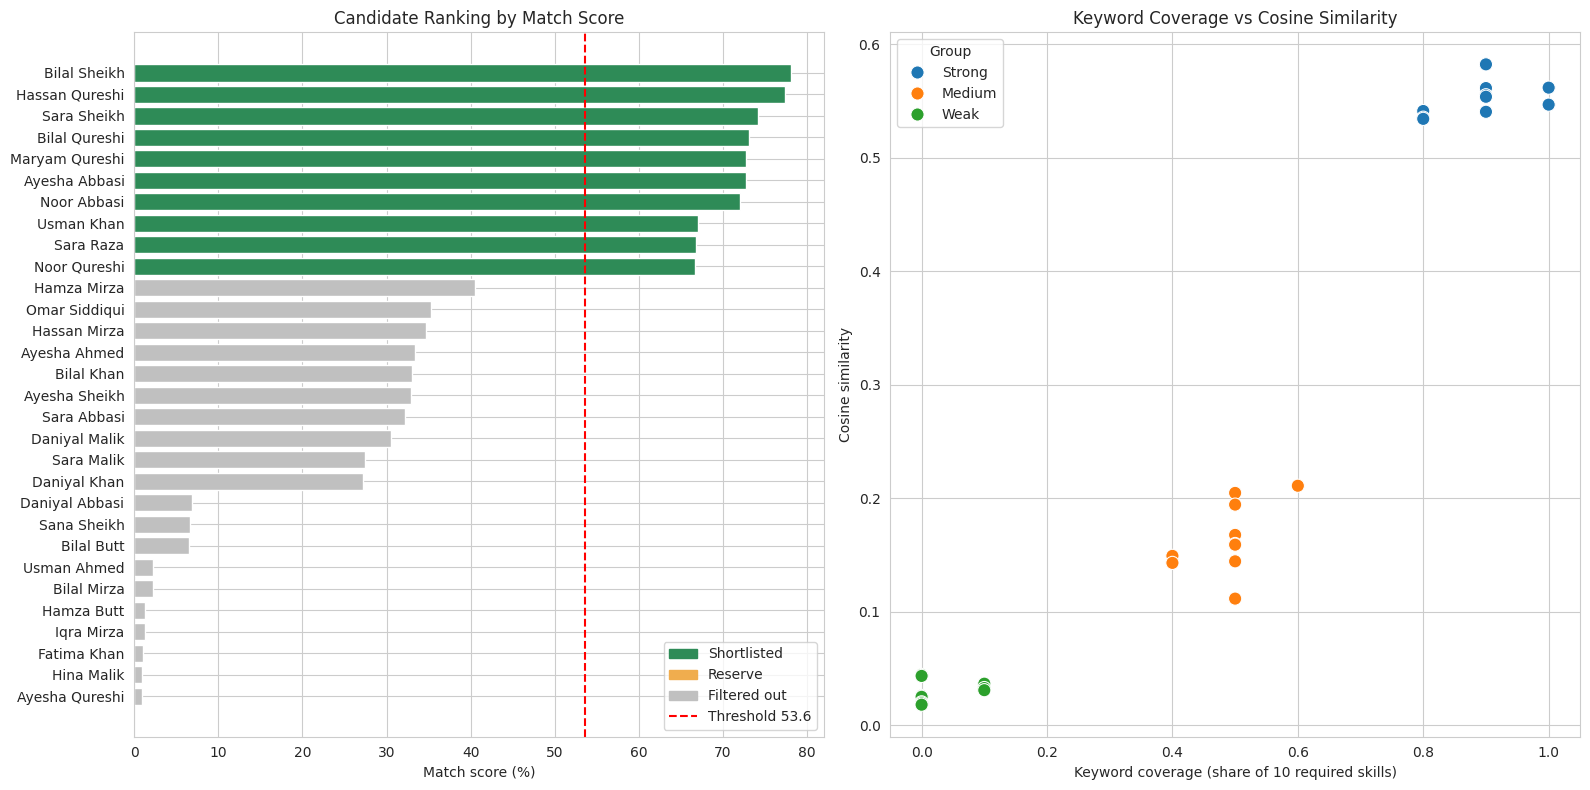

In [36]:
#Charts for your post
colors = {"Shortlisted": "#2e8b57", "Reserve": "#f0ad4e", "Filtered out": "#c0c0c0"}
plot_df = df.sort_values("Match_Score")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(plot_df["Name"], plot_df["Match_Score"],
             color=plot_df["Status"].map(colors))
axes[0].axvline(MIN_SCORE, color="red", linestyle="--", label=f"Threshold {MIN_SCORE}")
axes[0].set_title("Candidate Ranking by Match Score")
axes[0].set_xlabel("Match score (%)")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
               + [axes[0].lines[0]],
               labels=list(colors) + [f"Threshold {MIN_SCORE}"], loc="lower right")

sns.scatterplot(data=df, x="Keyword", y="Cosine", hue="Group",
                hue_order=["Strong", "Medium", "Weak"], s=90, ax=axes[1])
axes[1].set_title("Keyword Coverage vs Cosine Similarity")
axes[1].set_xlabel("Keyword coverage (share of 10 required skills)")
axes[1].set_ylabel("Cosine similarity")

plt.tight_layout()
plt.show()

In [37]:
#The final output and saved files
final = df[["Rank", "Name", "Match_Score", "Status", "Found", "Missing"]].copy()
final["Match_Score"] = final["Match_Score"].round(1)
final = final.rename(columns={"Match_Score": "Match_%", "Found": "Skills_found",
                              "Missing": "Skills_missing"})

final.to_csv("ranking.csv", index=False)
final[final["Status"] == "Shortlisted"].to_csv("shortlist.csv", index=False)

print("RANKING (top 12)")
print(final.head(12)[["Rank", "Name", "Match_%", "Status"]].to_string(index=False))

print("\nSHORTLISTED:", ", ".join(final.loc[final["Status"] == "Shortlisted", "Name"]))
print("RESERVE:    ", ", ".join(final.loc[final["Status"] == "Reserve", "Name"]) or "none")
print("FILTERED OUT:", (final["Status"] == "Filtered out").sum(), "candidates")

RANKING (top 12)
 Rank           Name  Match_%       Status
    1   Bilal Sheikh     78.1  Shortlisted
    2 Hassan Qureshi     77.3  Shortlisted
    3    Sara Sheikh     74.1  Shortlisted
    4  Bilal Qureshi     73.1  Shortlisted
    5 Maryam Qureshi     72.8  Shortlisted
    6  Ayesha Abbasi     72.7  Shortlisted
    7    Noor Abbasi     72.0  Shortlisted
    8     Usman Khan     67.1  Shortlisted
    9      Sara Raza     66.8  Shortlisted
   10   Noor Qureshi     66.7  Shortlisted
   11    Hamza Mirza     40.6 Filtered out
   12  Omar Siddiqui     35.2 Filtered out

SHORTLISTED: Bilal Sheikh, Hassan Qureshi, Sara Sheikh, Bilal Qureshi, Maryam Qureshi, Ayesha Abbasi, Noor Abbasi, Usman Khan, Sara Raza, Noor Qureshi
RESERVE:     none
FILTERED OUT: 20 candidates


In [39]:
#Get the files out of Colab
import shutil
from google.colab import files

shutil.make_archive("resumes", "zip", "resumes")
for f in ["job_description.txt", "required_skills.txt", "resumes.zip"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>